# Sesión 4 · Estadística aplicada a la incertidumbre de costes

**Preguntas de negocio:**
1. Para el presupuesto 2026, ¿qué coste de siniestros es razonable y qué rango de escenarios deberíamos contemplar?
2. A septiembre, ¿dónde cerraremos el año?
3. El canal Agentes tiene una siniestralidad del 79 % y Corredores del 67 %. **¿La diferencia es real o es ruido?**

> 🔑 **Versión con soluciones.**

| Bloque | Contenido | Min |
|---|---|---|
| 1 | Distribuciones: número de siniestros y coste por siniestro | 25 |
| 2 | Simulación Monte Carlo: presupuesto y forecast | 20 |
| 3 | Intervalos de confianza | 25 |
| 4 | Bootstrap: ¿la diferencia entre canales es real? | 20 |

**Idea central:** el coste de siniestros es la suma de **muchos eventos aleatorios**. Si entendemos *cuántos* hay (frecuencia) y *cuánto cuesta cada uno* (coste medio o severidad), podemos dar rangos en lugar de un único número.

In [1]:
# @title ⚙️ Ejecuta esta celda primero (prepara el entorno) { display-mode: "form" }
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/SSerraPe/curso-python-finanzas.git"
COPIA_DRIVE = Path("/content/drive/MyDrive/curso-python-finanzas")  # la crea el notebook 00
EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    try:
        drive.mount("/content/drive")
    except Exception as e:
        print("⚠️ No se ha podido conectar Google Drive:", e)
    if COPIA_DRIVE.is_dir():
        os.chdir(COPIA_DRIVE)
    else:
        print("⚠️ No encuentro tu copia del curso en Mi unidad › curso-python-finanzas (ver notebook 00).")
        print("   Uso una copia TEMPORAL: lo que generes se pierde al cerrar Colab.")
        if not Path("/content/curso-python-finanzas").exists():
            subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, "/content/curso-python-finanzas"], check=True)
        os.chdir("/content/curso-python-finanzas")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
else:
    # En tu ordenador: nos situamos en la carpeta raíz del curso (la que tiene data/ y src/)
    while not (Path("data").is_dir() and Path("src").is_dir()) and Path.cwd() != Path.cwd().parent:
        os.chdir("..")

sys.path.insert(0, str(Path("src").resolve()))
print("✅ Entorno listo. Carpeta de trabajo:", Path.cwd())

✅ Entorno listo. Carpeta de trabajo: /content/curso-python-finanzas


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from curso_seguros.datos import cargar_base_polizas, cargar_siniestros_referencia
from curso_seguros.kpis import ic_frecuencia
from curso_seguros.comprobar import comprobar

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
rng = np.random.default_rng(2025)         # semilla: resultados reproducibles

df = cargar_base_polizas()                # la tabla por póliza que construimos en la sesión 2
siniestros = cargar_siniestros_referencia()
importes = siniestros["importe"].to_numpy()
print(df.shape, len(importes))

(677991, 23) 26444


---
# Bloque 1 · Distribuciones

## 1.1 ¿Cuántos siniestros? La frecuencia

In [3]:
frecuencia = df["n_siniestros"].sum() / df["exposicion"].sum()
print(f"Frecuencia: {frecuencia:.4f} siniestros por año-póliza (≈ 1 de cada {1 / frecuencia:.0f} pólizas al año)")
df["n_siniestros"].value_counts().sort_index()

Frecuencia: 0.0738 siniestros por año-póliza (≈ 1 de cada 14 pólizas al año)


n_siniestros
0     653047
1      23571
2       1298
3         62
4          5
5          2
6          1
8          1
9          1
11         2
16         1
Name: count, dtype: int64

El modelo de referencia para contar eventos raros e independientes es la **distribución de Poisson**: si cada póliza tiene una tasa λ × exposición, la probabilidad de tener *k* siniestros es conocida. Comparemos lo **observado** con lo que predice Poisson:

In [4]:
lam = frecuencia * df["exposicion"].to_numpy()             # siniestros esperados por póliza
esperado = {k: stats.poisson.pmf(k, lam).sum() for k in range(5)}
observado = df["n_siniestros"].clip(upper=4).value_counts().sort_index()
pd.DataFrame({"observado": observado, "esperado Poisson": pd.Series(esperado)}).round(0)

,observado,esperado Poisson
0,653047,"652,291.0000"
1,23571,"24,971.0000"
2,1298,713.0000
3,62,15.0000
4,13,0.0000


Poisson acierta bastante con 0 y 1 siniestros, pero hay **más pólizas con 2+ siniestros** de lo esperado. Esto se llama **sobredispersión**: las pólizas no son todas iguales (unas son más arriesgadas que otras). La distribución **binomial negativa** recoge ese efecto. En la sesión 5 lo trataremos explicando la frecuencia con las características de cada póliza (GLM).

## 1.2 ¿Cuánto cuesta cada siniestro? La severidad

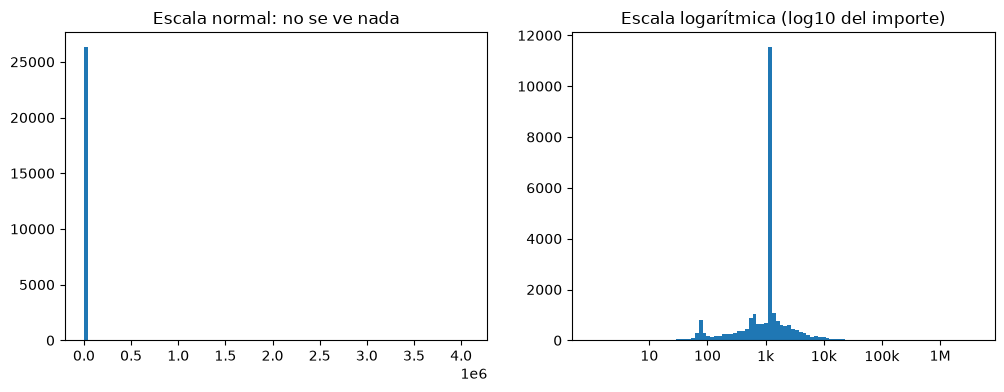

1,204.0000    4792
1,128.1200    3056
1,172.0000    2071
1,128.0000     831
602.0000       433
Name: count, dtype: int64

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(importes, bins=100)
ax[0].set_title("Escala normal: no se ve nada")
ax[1].hist(np.log10(importes), bins=100)
ax[1].set_title("Escala logarítmica (log10 del importe)")
ax[1].set_xticks([1, 2, 3, 4, 5, 6], ["10", "100", "1k", "10k", "100k", "1M"])
plt.show()

pd.Series(importes).value_counts().head(5)

Dos cosas importantes:
1. **Picos**: miles de siniestros cuestan exactamente 1.204 € o 1.128,12 €. Son importes **fijos de convenio** entre aseguradoras (en Francia, el convenio IRSA). Ningún modelo matemático "suave" los reproduce, y no pasa nada.
2. **Cola pesada**: unos pocos siniestros enormes.

In [6]:
orden = np.sort(importes)[::-1]
for pct in [0.001, 0.01, 0.05]:
    k = int(len(orden) * pct)
    print(f"El {pct:.1%} de siniestros más caros ({k}) = {orden[:k].sum() / orden.sum():.0%} del coste total")

El 0.1% de siniestros más caros (26) = 21% del coste total
El 1.0% de siniestros más caros (264) = 38% del coste total
El 5.0% de siniestros más caros (1322) = 52% del coste total


> 💡 **Lección para FP&A:** con colas así, el resultado de un trimestre puede depender de 3 o 4 siniestros. Por eso las aseguradoras separan los **siniestros grandes** en el reporting y los cubren con **reaseguro**.

## 1.3 Ajustar distribuciones con `scipy.stats`
Probamos tres candidatas habituales para importes positivos: **lognormal**, **gamma** y **Weibull**. `.fit()` estima los parámetros por **máxima verosimilitud** (los más compatibles con los datos).

⚠️ Siempre `floc=0`: fija el inicio de la distribución en 0 € (un importe no puede ser negativo).

In [7]:
candidatas = {"lognormal": stats.lognorm, "gamma": stats.gamma, "weibull": stats.weibull_min}
filas = []
for nombre, dist in candidatas.items():
    params = dist.fit(importes, floc=0)
    loglik = dist.logpdf(importes, *params).sum()
    filas.append({"distribución": nombre, "AIC": 2 * 2 - 2 * loglik,     # 2 parámetros libres
                  "media ajustada": dist.mean(*params),
                  "P(X > 100k) ajustada": dist.sf(100_000, *params),
                  "params": params})
ajustes = pd.DataFrame(filas).set_index("distribución")
ajustes.loc["empírico", ["media ajustada", "P(X > 100k) ajustada"]] = [importes.mean(), (importes > 100_000).mean()]
ajustes.drop(columns="params").style.format({"AIC": "{:,.0f}", "media ajustada": "{:,.0f} €",
                                               "P(X > 100k) ajustada": "{:.2e}"}, na_rep="—")

,AIC,media ajustada,P(X > 100k) ajustada
distribución,,,
lognormal,"443,620","1,781 €",1.82e-05
gamma,"458,667","2,266 €",1.60e-14
weibull,"451,420","1,912 €",2.11e-10
empírico,—,"2,266 €",1.55e-03


**Cómo leerlo:**
- El **AIC** mide el ajuste global (cuanto **menor**, mejor): gana la **lognormal**.
- Pero la lognormal da una **media de ~1.780 €, frente a 2.266 € reales**: infravalora el coste medio un 21 %, porque no capta la cola.
- La gamma reproduce la media (por construcción), pero ajusta peor la forma.

**El mejor ajuste "estadístico" no siempre es el que sirve para el negocio.** Si vas a usar el modelo para presupuestar costes, lo que importa es que acierte la **media** y la **cola**.

### El QQ-plot: el test visual
Si el modelo fuera perfecto, los puntos caerían sobre la diagonal.

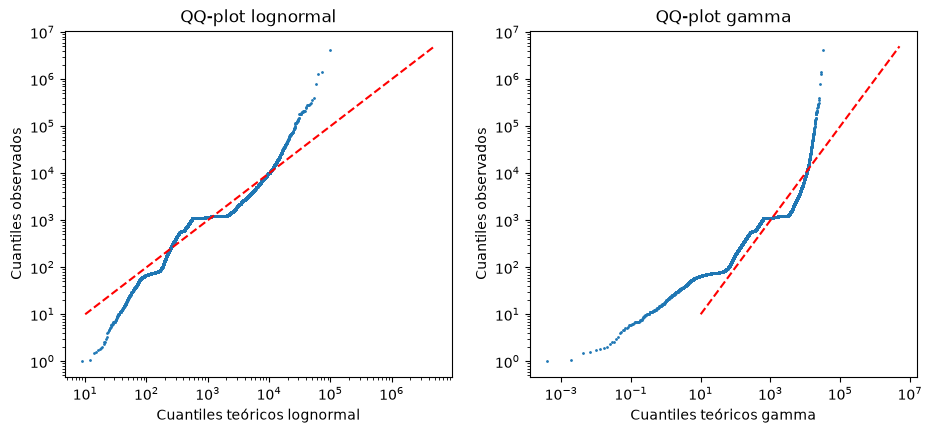

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
probs = (np.arange(1, len(importes) + 1) - 0.5) / len(importes)
for a, nombre in zip(ax, ["lognormal", "gamma"]):
    teo = candidatas[nombre].ppf(probs, *ajustes.loc[nombre, "params"])
    a.loglog(teo, np.sort(importes), ".", ms=2)
    a.plot([10, 5e6], [10, 5e6], "r--")
    a.set_xlabel(f"Cuantiles teóricos {nombre}")
    a.set_ylabel("Cuantiles observados")
    a.set_title(f"QQ-plot {nombre}")
plt.show()

En la lognormal, los puntos de la derecha (los siniestros más caros) quedan **por encima** de la diagonal: la realidad tiene siniestros más caros de lo que el modelo cree posible.

> Los tests formales (Kolmogorov-Smirnov…) **rechazan cualquier modelo** con 26.000 datos: con tanta información detectan cualquier desviación, por pequeña que sea. El p-valor responde a "¿hay alguna diferencia?", no a "¿me sirve el modelo?". Para decidir, mejor el QQ-plot y las métricas de negocio (media, cuantiles).

### ✏️ Ejercicio 1.1
Según la lognormal ajustada, ¿cuál es la probabilidad de que un siniestro supere 1 millón de €? Guárdala en `p_millon_lognormal`. Calcula también la proporción **real** en `p_millon_real`.

Pista: `stats.lognorm.sf(x, *params)` es P(X > x) ("sf" = *survival function*). Los parámetros están en `ajustes.loc["lognormal", "params"]`.

In [9]:
p_millon_lognormal = stats.lognorm.sf(1_000_000, *ajustes.loc["lognormal", "params"])
p_millon_real = (importes > 1_000_000).mean()
print(f"Lognormal: {p_millon_lognormal:.2e} | Real: {p_millon_real:.2e}  →  la lognormal se queda corta ~{p_millon_real / p_millon_lognormal:,.0f} veces")

Lognormal: 3.48e-10 | Real: 1.13e-04  →  la lognormal se queda corta ~326,216 veces


In [10]:
comprobar(lambda: p_millon_lognormal, stats.lognorm.sf(1e6, *ajustes.loc["lognormal", "params"]), "Usa .sf(1_000_000, *params)")
comprobar(lambda: p_millon_real, 3 / len(importes), "La media de un booleano es una proporción: (importes > 1e6).mean()")

✅ ¡Correcto!
✅ ¡Correcto!


---
# Bloque 2 · Simulación Monte Carlo

**Monte Carlo** = simular el año miles de veces y mirar la distribución de resultados. Es como hacer 10.000 escenarios en Excel, pero en un segundo.

En cada escenario:
1. Número de siniestros del año: N ~ Poisson(frecuencia × exposición prevista).
2. Importe de cada siniestro: se sortea de un modelo de severidad.
3. Coste anual = suma de los N importes.

Comparamos dos modelos de severidad: **lognormal ajustada** frente a **remuestreo empírico** (sortear entre los importes reales de 2025, que conserva los picos y la cola).

In [11]:
exposicion_2026 = df["exposicion"].sum()          # supuesto: misma exposición que en 2025
n_esperado = frecuencia * exposicion_2026
s_ln, _, escala_ln = ajustes.loc["lognormal", "params"]
N_ESCENARIOS = 5_000

coste_lognormal = np.empty(N_ESCENARIOS)
coste_empirico = np.empty(N_ESCENARIOS)
for i in range(N_ESCENARIOS):
    n = rng.poisson(n_esperado)
    coste_lognormal[i] = rng.lognormal(mean=np.log(escala_ln), sigma=s_ln, size=n).sum()
    coste_empirico[i] = rng.choice(importes, size=n, replace=True).sum()

resumen = pd.DataFrame({
    "lognormal": np.percentile(coste_lognormal, [5, 50, 90, 99]),
    "empírico": np.percentile(coste_empirico, [5, 50, 90, 99]),
}, index=["P5", "P50 (mediana)", "P90", "P99"]) / 1e6
resumen.style.format("{:,.1f} M€")

,lognormal,empírico
P5,46.2 M€,53.0 M€
P50 (mediana),47.1 M€,59.4 M€
P90,47.8 M€,66.7 M€
P99,48.4 M€,73.3 M€


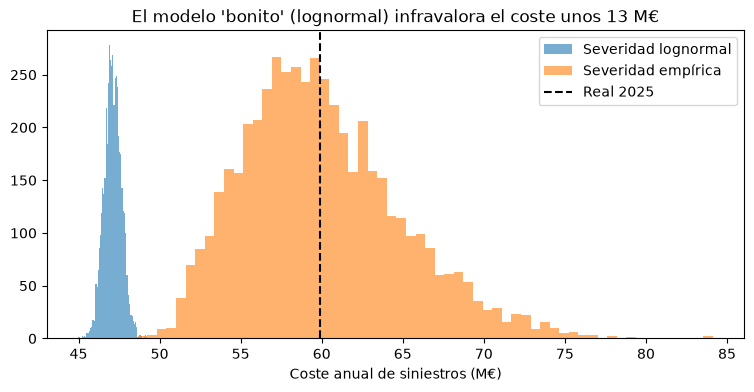

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(coste_lognormal / 1e6, bins=60, alpha=0.6, label="Severidad lognormal")
ax.hist(coste_empirico / 1e6, bins=60, alpha=0.6, label="Severidad empírica")
ax.axvline(siniestros["importe"].sum() / 1e6, color="k", ls="--", label="Real 2025")
ax.set_xlabel("Coste anual de siniestros (M€)")
ax.set_title("El modelo 'bonito' (lognormal) infravalora el coste unos 13 M€")
ax.legend()
plt.show()

**Para el presupuesto:**
- La **mediana** del escenario empírico es la cifra central defendible.
- El **P90 / P99** responde a "¿cuánto podría costarnos un mal año?" (1 de cada 10, 1 de cada 100). Es la base de una conversación sobre colchones, reaseguro y apetito de riesgo.
- La distribución es **asimétrica**: hay más recorrido hacia arriba que hacia abajo.

> El percentil 99,5 a un año es la medida que usa **Solvencia II** para el capital requerido ("una ruina cada 200 años").

### Forecast de cierre de año a septiembre
Conocemos el coste **real** declarado hasta el 30/09. Falta simular octubre–diciembre con la exposición que queda.

In [13]:
real_ytd = siniestros.loc[siniestros["fecha_declaracion"] <= "2025-09-30", "importe"].sum()

# exposición pendiente (oct-dic): días de cobertura posteriores al 30/09
corte = pd.Timestamp("2025-10-01")
dias_pend = (df["fecha_vencimiento"] - df["fecha_efecto"].clip(lower=corte)).dt.days.clip(lower=0)
expo_pendiente = (dias_pend / 365).sum()
primas_anuales = df["prima_devengada"].sum()

pendiente = np.array([rng.choice(importes, size=rng.poisson(frecuencia * expo_pendiente)).sum()
                      for _ in range(N_ESCENARIOS)])
cierre = real_ytd + pendiente
ratio_cierre = cierre / primas_anuales
print(f"Real a septiembre: {real_ytd / 1e6:,.1f} M€ | Exposición pendiente: {expo_pendiente:,.0f} años-póliza")
pd.Series(np.percentile(ratio_cierre, [10, 50, 90]), index=["P10", "P50", "P90"]).map("{:.1%}".format)

Real a septiembre: 45.5 M€ | Exposición pendiente: 74,926 años-póliza


P10    66.9%
P50    68.6%
P90    73.2%
dtype: object

En lugar de "cerraremos con un 72 % de siniestralidad", el mensaje es: **"cerraremos entre el X % y el Y % con un 80 % de confianza; escenario central Z %"**.

> Simplificación didáctica: ignoramos los siniestros ocurridos en 2025 que se declararán en 2026 (IBNR). El notebook complementario **C2** explica cómo se estiman.

### ✏️ Ejercicio 2.1
Usando `ratio_cierre`, calcula `prob_mas_75`: la probabilidad de que la siniestralidad de cierre supere el **75 %**.

In [14]:
prob_mas_75 = (ratio_cierre > 0.75).mean()
print(f"P(siniestralidad > 75 %) = {prob_mas_75:.1%}")

P(siniestralidad > 75 %) = 3.6%


In [15]:
comprobar(lambda: prob_mas_75, (ratio_cierre > 0.75).mean(), "La media de (ratio_cierre > 0.75) es la proporción de escenarios")

✅ ¡Correcto!


---
# Bloque 3 · Intervalos de confianza

Un **intervalo de confianza al 95 %** es un rango construido de forma que, si repitiéramos el año muchas veces, contendría el valor "verdadero" en el 95 % de los casos. Cuanto más **ancho**, menos sabemos.

## 3.1 Frecuencia por canal (Poisson)

In [16]:
por_canal = df.groupby("canal").agg(n=("n_siniestros", "sum"), expo=("exposicion", "sum"))
por_canal["frecuencia"] = por_canal["n"] / por_canal["expo"]
ic = [ic_frecuencia(n, e) for n, e in zip(por_canal["n"], por_canal["expo"])]
por_canal["ic_inf"], por_canal["ic_sup"] = zip(*ic)
por_canal["amplitud ±%"] = (por_canal["ic_sup"] - por_canal["ic_inf"]) / 2 / por_canal["frecuencia"]
por_canal

,n,expo,frecuencia,ic_inf,ic_sup,amplitud ±%
canal,,,,,,
Agentes,11334,"155,567.1452",0.0729,0.0715,0.0742,0.0185
Bancaseguros,2588,"35,205.8712",0.0735,0.0707,0.0764,0.0387
Corredores,6903,"94,040.5014",0.0734,0.0717,0.0752,0.0237
Directo,5619,"73,519.5534",0.0764,0.0744,0.0785,0.0262


### La regla de bolsillo: ±2/√N
La precisión relativa de una frecuencia depende **solo del número de siniestros** (N), no del número de pólizas:

| Siniestros observados | Precisión aproximada (95 %) |
|---|---|
| 100 | ±20 % |
| 400 | ±10 % |
| 1.000 | ±6 % |
| 10.000 | ±2 % |

¿Un segmento con 50 siniestros "ha empeorado un 15 %"? Eso está **dentro del ruido**.

## 3.2 Coste medio (intervalo t)

In [17]:
def ic_media(x, nivel=0.95):
    x = np.asarray(x)
    m, se = x.mean(), x.std(ddof=1) / np.sqrt(len(x))
    t = stats.t.ppf(0.5 + nivel / 2, df=len(x) - 1)
    return m, m - t * se, m + t * se

filas = []
for canal, g in siniestros.groupby("canal"):
    m, lo, hi = ic_media(g["importe"])
    filas.append({"canal": canal, "n": len(g), "coste_medio": m, "ic_inf": lo, "ic_sup": hi})
pd.DataFrame(filas).set_index("canal")

,n,coste_medio,ic_inf,ic_sup
canal,,,,
Agentes,11334,"2,512.0020","1,747.7139","3,276.2901"
Bancaseguros,2588,"1,867.2928","1,576.5625","2,158.0230"
Corredores,6903,"2,079.1313","1,781.0303","2,377.2323"
Directo,5619,"2,180.7063","1,683.1947","2,678.2179"


Los intervalos del coste medio son **mucho más anchos** que los de frecuencia: la cola pesada mete mucha incertidumbre. (Con colas tan extremas, además, la aproximación normal del intervalo t es optimista.)

### ✏️ Ejercicio 3.1
Calcula la frecuencia y su IC al 95 % para los conductores de **18–25 años** y para el **resto**, usando `ic_frecuencia(n, exposicion)`. Guarda los resultados en `ic_jovenes` e `ic_resto` (tuplas `(inferior, superior)`). ¿Se solapan?

In [18]:
jov = df[df["tramo_edad"] == "18-25"]
resto = df[df["tramo_edad"] != "18-25"]
ic_jovenes = ic_frecuencia(jov["n_siniestros"].sum(), jov["exposicion"].sum())
ic_resto = ic_frecuencia(resto["n_siniestros"].sum(), resto["exposicion"].sum())
print(f"18-25: [{ic_jovenes[0]:.3f}, {ic_jovenes[1]:.3f}] | Resto: [{ic_resto[0]:.3f}, {ic_resto[1]:.3f}]")

18-25: [0.142, 0.154] | Resto: [0.069, 0.071]


In [19]:
_j = df[df["tramo_edad"] == "18-25"]
comprobar(lambda: ic_jovenes[0], ic_frecuencia(_j["n_siniestros"].sum(), _j["exposicion"].sum())[0],
          "Filtra tramo_edad == '18-25' y pasa la suma de siniestros y de exposición")

✅ ¡Correcto!


**Conclusión:** la frecuencia de los jóvenes (~15 %) **duplica** la del resto (~7 %) y los intervalos ni se tocan. Esa diferencia es **estructural**, no ruido.

---
# Bloque 4 · Bootstrap: ¿la diferencia entre canales es real?

Para un ratio como la siniestralidad (Σ costes / Σ primas) no hay una fórmula sencilla del intervalo. El **bootstrap** lo resuelve por simulación:

1. Remuestrear las **pólizas** del canal con reemplazo (mismo tamaño).
2. Recalcular la siniestralidad con esa muestra.
3. Repetir 1.000 veces → el rango entre los percentiles 2,5 y 97,5 es el IC al 95 %.

> Se remuestrean **pólizas** (no siniestros) para que cada muestra conserve juntos su prima y su coste.

In [20]:
def bootstrap_siniestralidad(datos, n_rep=1000, semilla=0):
    r = np.random.default_rng(semilla)
    coste, prima = datos["coste_siniestros"].to_numpy(), datos["prima_devengada"].to_numpy()
    n = len(coste)
    sims = np.empty(n_rep)
    for b in range(n_rep):
        idx = r.integers(0, n, n)                   # índices sorteados con reemplazo
        sims[b] = coste[idx].sum() / prima[idx].sum()
    return sims

boot = {canal: bootstrap_siniestralidad(g) for canal, g in df.groupby("canal")}
tabla_boot = pd.DataFrame({
    "siniestralidad": df.groupby("canal").apply(lambda g: g["coste_siniestros"].sum() / g["prima_devengada"].sum(),
                                                include_groups=False),
    "ic_inf": {c: np.percentile(s, 2.5) for c, s in boot.items()},
    "ic_sup": {c: np.percentile(s, 97.5) for c, s in boot.items()},
})
tabla_boot.style.format("{:.1%}")

,siniestralidad,ic_inf,ic_sup
Agentes,78.6%,60.8%,105.2%
Bancaseguros,56.5%,48.6%,67.1%
Corredores,67.3%,59.2%,77.8%
Directo,70.3%,57.5%,88.0%


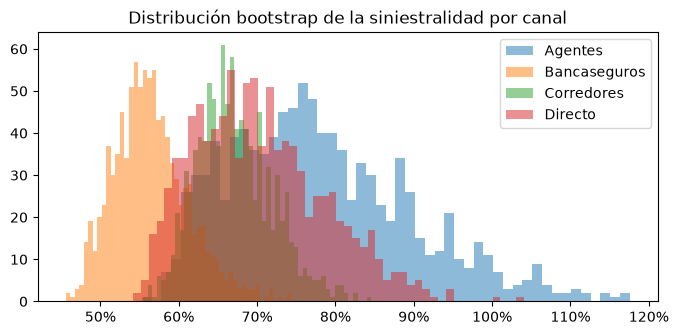

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for canal, s in boot.items():
    ax.hist(s, bins=50, alpha=0.5, label=canal)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Distribución bootstrap de la siniestralidad por canal")
ax.legend()
plt.show()

### La diferencia Agentes − Corredores
Como los dos canales son muestras independientes, restamos sus simulaciones:

In [22]:
diferencia = boot["Agentes"] - boot["Corredores"]
print(f"Diferencia observada: {tabla_boot.loc['Agentes', 'siniestralidad'] - tabla_boot.loc['Corredores', 'siniestralidad']:+.1%}")
print(f"IC 95 % de la diferencia: [{np.percentile(diferencia, 2.5):+.1%}, {np.percentile(diferencia, 97.5):+.1%}]")
print(f"% de simulaciones en que Agentes es peor: {(diferencia > 0).mean():.0%}")

Diferencia observada: +11.4%
IC 95 % de la diferencia: [-9.0%, +38.6%]
% de simulaciones en que Agentes es peor: 80%


**Lectura honesta para Dirección:** el intervalo de la diferencia **incluye el 0**. Con los datos de un año no podemos afirmar, con un 95 % de confianza, que Agentes tenga peor siniestralidad que Corredores. Gran parte del gap viene de unos pocos siniestros enormes.

Lo que sí es sólido es que los jóvenes tienen **el doble de frecuencia** (bloque 3). Pero antes de concluir "hay que subirles el precio", falta una pregunta: **¿la tarifa actual ya se lo cobra por otra vía?** (Por ejemplo, el bonus-malus: un conductor novel empieza sin bonificación). Separar los efectos de varias variables a la vez es justo lo que hace un GLM. → Sesión 5.

### `scipy.stats.bootstrap` (versión de librería)
Lo mismo en una llamada. `paired=True` remuestrea las pólizas manteniendo juntos coste y prima. Con cientos de miles de filas usamos `method="percentile"`, porque el método por defecto (BCa) es muy lento con muestras grandes.

In [23]:
banca = df[df["canal"] == "Bancaseguros"]
res = stats.bootstrap((banca["coste_siniestros"].to_numpy(), banca["prima_devengada"].to_numpy()),
                      statistic=lambda c, p: c.sum() / p.sum(), paired=True, vectorized=False,
                      n_resamples=500, method="percentile", random_state=1)
print(f"Bancaseguros: IC 95 % = [{res.confidence_interval.low:.1%}, {res.confidence_interval.high:.1%}]")

Bancaseguros: IC 95 % = [47.9%, 65.8%]


### ✏️ Ejercicio 4.1
Calcula con `bootstrap_siniestralidad` el IC al 95 % de la siniestralidad de **Agentes, 18–25 años** (observada: ~365 %). Guarda los límites en `ic_ag_jov = (inferior, superior)`.

In [24]:
seg = df[(df["canal"] == "Agentes") & (df["tramo_edad"] == "18-25")]
sims = bootstrap_siniestralidad(seg)
ic_ag_jov = (np.percentile(sims, 2.5), np.percentile(sims, 97.5))
print(f"IC 95 %: [{ic_ag_jov[0]:.0%}, {ic_ag_jov[1]:.0%}]")

IC 95 %: [85%, 853%]


In [25]:
_s = bootstrap_siniestralidad(df[(df["canal"] == "Agentes") & (df["tramo_edad"] == "18-25")])
comprobar(lambda: ic_ag_jov[1], np.percentile(_s, 97.5), "Usa bootstrap_siniestralidad(seg) con la semilla por defecto y los percentiles 2.5 y 97.5", rtol=1e-6)

✅ ¡Correcto!


Un intervalo que va de menos del 100 % a más del 800 % significa que **ese número no sirve para tomar decisiones** por sí solo.

### ⚠️ Cuándo falla el bootstrap
El bootstrap solo puede "imaginar" lo que ya ha visto: **nunca genera un siniestro mayor que el máximo observado**. Con colas muy pesadas y pocos datos tiende a **infravalorar** la incertidumbre. Ejemplo: sin el siniestro de 4 M€, el mismo segmento parece mucho más tranquilo.

In [26]:
seg_sin_max = seg.copy()
seg_sin_max.loc[seg_sin_max["coste_siniestros"].idxmax(), "coste_siniestros"] = 0
s2 = bootstrap_siniestralidad(seg_sin_max)
print(f"Sin el siniestro máximo: {seg_sin_max['coste_siniestros'].sum() / seg_sin_max['prima_devengada'].sum():.0%} "
      f"IC [{np.percentile(s2, 2.5):.0%}, {np.percentile(s2, 97.5):.0%}]")

Sin el siniestro máximo: 171% IC [76%, 333%]


---
## Resumen de la sesión
- El coste de siniestros = **frecuencia × severidad**. La frecuencia es estable; la severidad tiene **cola pesada**.
- El mejor ajuste por AIC puede **infravalorar la media**: valida los modelos con métricas de negocio.
- **Monte Carlo** convierte un número de presupuesto en un **rango** (P50 / P90 / P99) y permite hacer forecasts con incertidumbre.
- Regla **±2/√N**: la precisión depende del número de siniestros.
- **Bootstrap** para ratios: antes de afirmar que un canal "es peor", comprueba si el IC de la diferencia incluye el 0.

**Próxima sesión:** pasar de "los jóvenes son más caros" a **por qué** y **cuánto**, controlando todo lo demás a la vez (GLM), y qué segmentos destruyen margen.